# Map-to-Image Change Detection

*Section 6 — Change detection, notebook 4 of 5.* Previous: `03_image_to_image_change`. Next: `05_multivariate_change_detection`.

**You will learn:**
- how to find the pixels of a class that have changed by looking for outliers in a new image, with `find_class_kurt_skew_outliers`;
- how to update the baseline classification with those changes;
- how to plot the histogram of a class's pixels with the threshold found, with `plot_img_histogram`;
- how to create a from–to change map from the updated classification, named and coloured with `set_thematic_classes`.

**Before you start:** run `01_create_baseline_class` and `02_map_to_map_change` first; this notebook reads the 1997 classification from `outputs/baseline_cls` and the 2018 valid-data mask from `outputs/2018_cls`.

**Data:** `../data/chg_data/LS8_20180608_vmsk_mclds_topshad_rad_srefdem_stdsref_subset.tif` (Landsat 8, 2018).

**Run time:** about 1 minute.

## What is Map-to-Image Change?

Probably the least explored method, here an existing classification at the first date is required but rather than undertaking a second independent classification, a method which compares the image and map is used to identify the change pixels and then classifies them to update the existing map. These methods **have few assumptions** but generally **expect the area of change to be small** compared to the not changed regions. When a change occurs there is also an **assumption that the change causes the EO signal (reflectance, backscatter etc.) to change, being identifiable when compared to the original class**.

## What are the steps:

Again, this is quite simple. We need a classification and a new input image from a different date and we will try to use that input image to find the changes between the two dates.

## 1. Define Imports

In [1]:
%matplotlib inline

import os

import matplotlib.pyplot as plt

import rsgispy
import rsgispy.changedetect.pxloutlierchng as poc
from rsgispy.imagecalc.calcindices import calc_indices
from rsgispy.imagecalc.maths import BandDefn, band_maths
from rsgispy.imageutils.colourtable import set_thematic_classes
from rsgispy.mapping.raster import create_thematic_raster_map
from rsgispy.tools.plotting import plot_img_histogram

## 2. Define Input Images and Directories

In [2]:
# The outputs of notebooks 01 and 02.
cls_1997_dir = os.path.join("outputs", "baseline_cls")
cls_2018_dir = os.path.join("outputs", "2018_cls")

map_to_img_chg_dir = os.path.join("outputs", "map_to_img_chg")
os.makedirs(map_to_img_chg_dir, exist_ok=True)

# File path to the 1997 classification
cls_1997_img = os.path.join(cls_1997_dir, "base_1997_class_img.tif")

# File path to the input Landsat 8 image from 2018.
input_18_img = (
    "../data/chg_data/LS8_20180608_vmsk_mclds_topshad_rad_srefdem_stdsref_subset.tif"
)

# File path to the Landsat 8 valid data mask from 2018.
vld_18_img = os.path.join(cls_2018_dir, "LS8_20180608_vmsk.tif")

## 3. Calculate NDVI for 2018

For Landsat 8, red is band 4 and NIR is band 5.

In [3]:
ls_2018_ndvi_img = os.path.join(map_to_img_chg_dir, "LS8_20180608_ndvi.tif")
calc_indices(
    input_18_img,
    ls_2018_ndvi_img,
    band_names={4: "red", 5: "nir"},
    indices=["NDVI"],
    no_data_val=0,
    out_no_data_val=-999.0,
    use_pbar=False,
)

## 4. Identify Mangrove Change Features

`find_class_kurt_skew_outliers` takes the 2018 NDVI values of the pixels which were mangroves in 1997 (`img_mask_val=1`) and searches for the threshold which makes the remaining (non-outlier) distribution closest to a normal distribution (i.e., minimises the absolute skewness plus kurtosis). The arguments are:

- the valid range of the values (`vld_min=-1`, `vld_max=1` for NDVI);
- an initial estimate of the threshold (`0.35`);
- `low_thres=True`: for mangroves the change (loss) is to **lower** NDVI values;
- `contamination=10.0`: an estimate of the percentage of outliers (change);
- `only_kurtosis=False`: optimise kurtosis and skewness together.

The output image has the values 0 (not in the class), 1 (in the class, no change) and 2 (in the class, change). The function returns the threshold it found. `plot_img_histogram` then plots the histogram of the 2018 NDVI of the class's pixels (those where the 1997 classification is `img_msk_val`) with the threshold.

Mangrove NDVI change threshold: 0.685


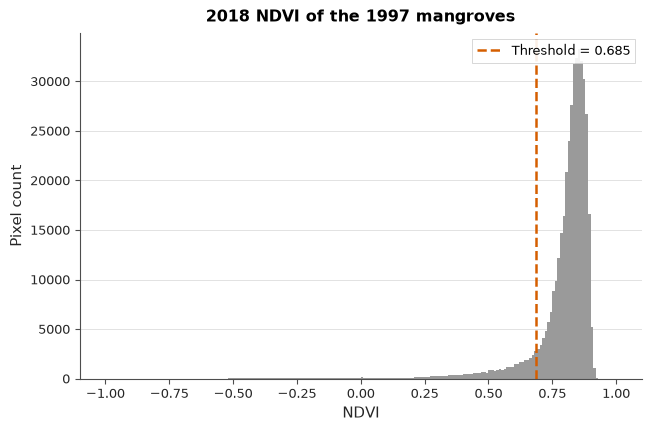

In [4]:
out_mng_chng_msk = os.path.join(map_to_img_chg_dir, "mng_2018_map2img_chngs.tif")

mng_thres = poc.find_class_kurt_skew_outliers(
    ls_2018_ndvi_img,
    cls_1997_img,
    out_mng_chng_msk,
    -1,
    1,
    0.35,
    True,
    10.0,
    False,
    img_mask_val=1,  # Specify mangrove class
    img_band=1,
    use_pbar=False,
)
print(f"Mangrove NDVI change threshold: {mng_thres:.3f}")

fig, ax = plot_img_histogram(
    ls_2018_ndvi_img,
    val_range=(-1, 1),
    in_msk_img=cls_1997_img,
    img_msk_val=1,
    thresholds=mng_thres,
    title="2018 NDVI of the 1997 mangroves",
    x_label="NDVI",
    use_pbar=False,
)

## 5. Identify Water Change Features

For water (`img_mask_val=3`) the change (to mangroves) is to **higher** NDVI values, so `low_thres=False`.

Water NDVI change threshold: 0.214


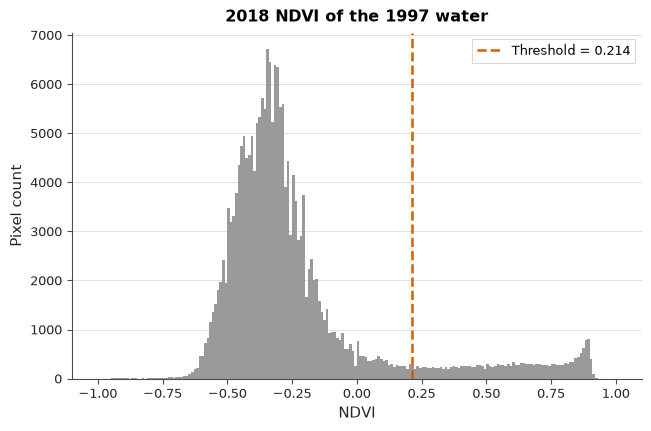

In [5]:
out_water_chng_msk = os.path.join(map_to_img_chg_dir, "water_2018_map2img_chngs.tif")

water_thres = poc.find_class_kurt_skew_outliers(
    ls_2018_ndvi_img,
    cls_1997_img,
    out_water_chng_msk,
    -1,
    1,
    0.35,
    False,
    10.0,
    False,
    img_mask_val=3,  # Specify water class
    img_band=1,
    use_pbar=False,
)
print(f"Water NDVI change threshold: {water_thres:.3f}")

fig, ax = plot_img_histogram(
    ls_2018_ndvi_img,
    val_range=(-1, 1),
    in_msk_img=cls_1997_img,
    img_msk_val=3,
    thresholds=water_thres,
    title="2018 NDVI of the 1997 water",
    x_label="NDVI",
    use_pbar=False,
)

## 6. Update 1997 Classification to 2018

Mangrove pixels identified as change become water, and water pixels identified as change become mangroves; all other pixels keep their 1997 class.

In [6]:
chng_2018_cls_img = os.path.join(map_to_img_chg_dir, "chng_map_2018_map2img.tif")

band_defns = [
    BandDefn("vld_18_msk", vld_18_img, 1),
    BandDefn("cls_1997", cls_1997_img, 1),
    BandDefn("mng_chng", out_mng_chng_msk, 1),
    BandDefn("wat_chng", out_water_chng_msk, 1),
]
exp = """(vld_18_msk==1)&&(cls_1997==1)&&(mng_chng==2)?3:
         (vld_18_msk==1)&&(cls_1997==3)&&(wat_chng==2)?1:
         cls_1997
      """
band_maths(chng_2018_cls_img, exp, band_defns, datatype=rsgispy.TYPE_8UINT, use_pbar=False)
# The classes of the classifications (as in notebooks 01 and 02).
cls_info = {
    1: ("mangroves", (0, 255, 0)),
    2: ("other_terrestrial", (180, 180, 180)),
    3: ("water", (0, 0, 255)),
}
set_thematic_classes(chng_2018_cls_img, cls_info)

## 7. Create Change Image

In [7]:
# Define output image path
chng_map_img = os.path.join(map_to_img_chg_dir, "chng_map_1997_2018_map2img.tif")

# Define the input image bands
band_defns = [
    BandDefn("cls_1997", cls_1997_img, 1),
    BandDefn("cls_2018", chng_2018_cls_img, 1),
]

# Expression to define change classes
exp = """(cls_1997==1)&&(cls_2018==1)?11:
         (cls_1997==1)&&(cls_2018==2)?12:
         (cls_1997==1)&&(cls_2018==3)?13:
         (cls_1997==2)&&(cls_2018==1)?21:
         (cls_1997==2)&&(cls_2018==2)?22:
         (cls_1997==2)&&(cls_2018==3)?23:
         (cls_1997==3)&&(cls_2018==1)?31:
         (cls_1997==3)&&(cls_2018==2)?32:
         (cls_1997==3)&&(cls_2018==3)?33:0
      """

# Run band_maths
band_maths(chng_map_img, exp, band_defns, datatype=rsgispy.TYPE_8UINT, use_pbar=False)


## 8. Colour and Name Change Classes

`set_thematic_classes` writes the colours to the colour table, stores the names in the image and calculates the statistics and pyramids; the map legend reads the names from the image.

**RSGISLib users:** this replaces `rastergis.set_class_names_colours`.

In [8]:
# pixel value: (class name, (red, green, blue))
chng_cls_info = {
    11: ("Mangrove_Mangrove", (25, 200, 25)),
    12: ("Mangrove_Terrestrial", (200, 100, 25)),
    13: ("Mangrove_Water", (200, 25, 200)),
    21: ("Terrestrial_Mangrove", (125, 100, 125)),
    22: ("Terrestrial_Terrestrial", (125, 125, 125)),
    23: ("Terrestrial_Water", (125, 125, 100)),
    31: ("Water_Mangrove", (25, 255, 200)),
    32: ("Water_Terrestrial", (62, 62, 200)),
    33: ("Water_Water", (25, 25, 200)),
}
set_thematic_classes(chng_map_img, chng_cls_info)

## 9. Visualise Change Result

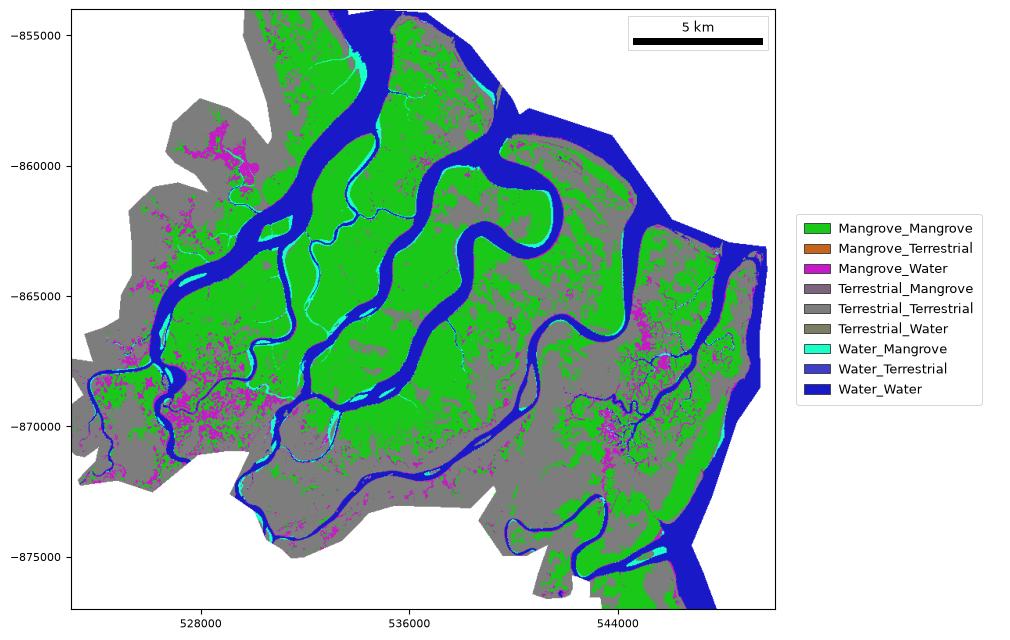

In [9]:
sub_bbox = [523000, 550000, -877000, -854000]

fig, ax = plt.subplots(figsize=(12, 10))

# Plot the change result
img = create_thematic_raster_map(
    ax,
    chng_map_img,
    bbox=sub_bbox,
    show_legend=True,
    legend_ncols=1,
)